# Final run: test-set evaluation

**Question.** On held-out data, how well do the final models recover the true gas concentrations, compared with the hour of day alone and with the best the bins allow?

**Models** (all on the same splits, bins and test hours):

| Model | Network | Gases |
|---|---|---|
| HourOnlyBaseline | hour → gas | CO, NOx, NO2 |
| Phase 1 | hour → CO → S1, S3, S4, S5 ← T, RH | CO only |
| Phase 3b | hour, weekday → R (K = 3) → CO, NOx, NO2 → sensors (nominal + cross edges) ← T, RH | CO, NOx, NO2 |

Phases 2 and 3a are not refit here. They justify each added piece of structure on validation; this notebook scores only the baseline, the simplest BN and the final model.

**Setup.**
- Data: UCI Air Quality, rows with a missing hour or weather dropped, as in every phase.
- Splits: `blocked_split` seeds 0, 1, 2 (whole weeks shuffled into train / val / test). For each seed the models are fit on **train ∪ val** and scored on **test**. Train ∪ val and test share no 7-day block.
- Bins: 3 and 5 quantile bins, edges and bin means c̄ₖ learned on train ∪ val only.
- Models: Phase 1 and Phase 3b use `LayeredBN` (MAP-EM, Laplace α from the config). Phase 3b keeps the best of 5 EM restarts by the fit objective, never by test.
- Configuration: fixed by the phase notebooks on validation (K = 3, Event-only, is_weekday; α = 1). Nothing is chosen here.

**Metrics** (per gas, on test hours with a reference reading):
- **MAE** of the concentration estimate ĉ = Σₖ P(bin k | evidence) · c̄ₖ, in the gas's units (CO mg/m³, NOx ppb, NO2 µg/m³). The headline metric.
- **Floor MAE**: the resolution floor, the error of a perfect bin prediction that puts every hour at its true bin's c̄ₖ. The best these bins allow.
- **Excess over floor** = MAE − floor MAE: the part of the error the model, not the bins, is responsible for.
- **Skill** = 1 − MAE / MAE_hour and **gap closed** = (MAE_hour − MAE) / (MAE_hour − floor).
- **Mean log-likelihood** of the true bin (comparable only at the same bin count).

**Rule.** Test is read in one cell (section 5), after every model is fitted. No model or setting is changed after these numbers have been seen.

**Outputs:** `results/final/test_grid.csv` (one row per bins, seed, gas, model), `results/final/test_summary.csv`, figures in `figures/final/`.

## 1. Setup

In [ ]:
%load_ext autoreload
%autoreload 2

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cse250a.modules.config import config
from cse250a.modules.core import TIME_CARDS, Gas, Latent, Network, Sensor, Time, Weather
from cse250a.modules.data import Discretizer, blocked_split, load_air_quality
from cse250a.modules.eval import (
    bin_means,
    concentration_error,
    expected_concentration,
    resolution_floor,
    score,
)
from cse250a.modules.eval.skill import skill_table, skill_vs_baseline
from cse250a.modules.models import HourOnlyBaseline, LayeredBN

PHASE = "final"
SEEDS = (0, 1, 2)
BIN_COUNTS = (config.bins.n_bins, 5)  # 3 and 5, as in every phase
ALPHA = config.bins.alpha
RESTART_SEEDS = (0, 1, 2, 3, 4)  # Phase 3b: best of 5 EM restarts, as in its notebook

MODELS = ("HourOnlyBaseline", "Phase1", "Phase3b")
UNITS = {"CO": "mg/m³", "NOx": "ppb", "NO2": "µg/m³"}
COLORS = {
    "HourOnlyBaseline": "#9E9E9E",
    "Phase1": "#64B5F6",
    "Phase3b": "#2E7D32",
    "resolution_floor": "#455A64",
}

plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)

## 2. Data

The same variables and row filter as every phase notebook. Hour, weekday and weather are inputs with no CPT, so rows missing them are dropped; rows missing a gas reference are kept (EM uses them in fitting, and they are simply not scored).

In [ ]:
df = load_air_quality(config.paths.air_quality_csv)

GASES = (Gas.CO, Gas.NOX, Gas.NO2)
SENSORS = (Sensor.S1, Sensor.S3, Sensor.S4, Sensor.S5)
WEATHER = (Weather.T, Weather.RH)

before = len(df)
df = df.dropna(subset=[Time.HOUR, *WEATHER])
print(f"dropped {before - len(df)} rows with missing hour/weather; {len(df)} left")


def short(gas):
    """'CO(GT)' -> 'CO'."""
    return str(gas).split("(")[0]

dropped 366 rows with missing hour/weather; 8991 left


## 3. Networks

Copied from the phase notebooks; they must stay identical to them.

- **Phase 1** (`notebooks/phase1/eval.ipynb`, `make_network`): CO depends on the hour; every sensor depends on CO and the weather.
- **Phase 3b** (`notebooks/phase3b/eval.ipynb`, `event_network` with `CHOSEN`): hour and weekday → R; R → each gas (Event-only); nominal edges S1 ← CO, S3 ← NOx, S4 ← NO2, cross edges S4 ← CO, NOx and S5 ← CO, NOx; T and RH → every sensor.

Each model gets only what a deployed device sees as evidence, never a gas reference.

In [ ]:
R = Latent.EMISSION_REGIME
CHOSEN = {"K": 3, "day": Time.IS_WEEKDAY}  # phase3b: K = 3, Event-only, is_weekday

NOMINAL = {Sensor.S1: (Gas.CO,), Sensor.S3: (Gas.NOX,), Sensor.S4: (Gas.NO2,)}
CROSS = {Sensor.S4: (Gas.CO, Gas.NOX), Sensor.S5: (Gas.CO, Gas.NOX)}


def phase1_network(cards):
    """notebooks/phase1/eval.ipynb: hour → CO → every sensor ← T, RH."""
    return Network(
        structure={Gas.CO: (Time.HOUR,), **{s: (Gas.CO, *WEATHER) for s in SENSORS}},
        cards=cards,
    )


def phase3b_network(cards):
    """notebooks/phase3b/eval.ipynb: event_network(K=3, "event", is_weekday)."""
    sensor_parents = {
        s: (*NOMINAL.get(s, ()), *CROSS.get(s, ()), *WEATHER) for s in SENSORS
    }
    return Network(
        structure={
            R: (Time.HOUR, CHOSEN["day"]),
            **{g: (R,) for g in GASES},
            **sensor_parents,
        },
        cards={**cards, R: CHOSEN["K"]},
        latent=(R,),
    )


EVIDENCE = {
    "HourOnlyBaseline": (Time.HOUR, *WEATHER, *SENSORS),  # reads only the hour
    "Phase1": (Time.HOUR, *WEATHER, *SENSORS),
    "Phase3b": (Time.HOUR, Time.IS_WEEKDAY, *WEATHER, *SENSORS),
}
TARGETS = {"HourOnlyBaseline": GASES, "Phase1": (Gas.CO,), "Phase3b": GASES}

## 4. Splits and fitting

For each (bins, seed): split by week, merge train and val into one **fit** set, learn the bin edges and bin means on fit only, and fit the three models on fit. Test is transformed with the fit edges but not read until section 5.

In [ ]:
def make_split(seed, n_bins):
    """fit = train ∪ val; everything learned from data uses fit only."""
    train_raw, val_raw, test_raw = blocked_split(df, seed=seed)
    fit_raw = pd.concat([train_raw, val_raw]).sort_index()
    disc = Discretizer(n_bins=n_bins).fit(fit_raw, [*GASES, *SENSORS, *WEATHER])
    fit, test = disc.transform(fit_raw), disc.transform(test_raw)
    return {
        "fit_raw": fit_raw,
        "test_raw": test_raw,
        "fit": fit,
        "test": test,
        "cards": {**disc.cards, **TIME_CARDS},
        "disc": disc,
        "c_bar": {g: bin_means(fit_raw[g], fit[g]) for g in GASES},
    }


splits = {(b, s): make_split(s, b) for b in BIN_COUNTS for s in SEEDS}


# no 7-day block (as blocked_split counts them, from the first hour) is in both fit and test
def block_ids(index):
    return set((index - df.index[0]) // pd.Timedelta("7D"))


for (b, s), sp in splits.items():
    shared = block_ids(sp["fit_raw"].index) & block_ids(sp["test_raw"].index)
    assert not shared, f"bins={b} seed={s}: fit and test share blocks {shared}"

pd.DataFrame(
    {
        f"seed {s}": {
            "fit hours": len(sp["fit_raw"]),
            "test hours": len(sp["test_raw"]),
            **{
                f"test {short(g)} readings": int(sp["test_raw"][g].notna().sum())
                for g in GASES
            },
        }
        for (b, s), sp in splits.items()
        if b == BIN_COUNTS[0]
    }
)

,seed 0,seed 1,seed 2
fit hours,6759,6719,6649
test hours,2232,2272,2342
test CO readings,1643,1848,1762
test NOx readings,1657,1865,1806
test NO2 readings,1656,1864,1805


In [ ]:
def fit_phase3b(sp):
    """Best of RESTART_SEEDS by the fit objective (log-lik + log-prior on train ∪ val)."""
    net = phase3b_network(sp["cards"]).validate(sp["fit"].columns)
    fits = [
        LayeredBN(net, alpha=ALPHA, max_iter=200, seed=r).fit(sp["fit"])
        for r in RESTART_SEEDS
    ]
    return max(fits, key=lambda bn: bn.result.final)


models, fit_log = {}, []
for (b, s), sp in splits.items():
    t0 = time.perf_counter()
    p1 = LayeredBN(
        phase1_network(sp["cards"]).validate(sp["fit"].columns), alpha=ALPHA
    ).fit(sp["fit"])
    p3b = fit_phase3b(sp)
    models[(b, s)] = {
        "HourOnlyBaseline": HourOnlyBaseline(cards=sp["cards"], alpha=ALPHA).fit(
            sp["fit"]
        ),
        "Phase1": p1,
        "Phase3b": p3b,
    }
    for name, bn in (("Phase1", p1), ("Phase3b", p3b)):
        fit_log.append(
            {
                "bins": b,
                "seed": s,
                "model": name,
                "iterations": bn.result.n_iter,
                "converged": bn.result.converged,
                "monotone": bn.result.is_monotone(),
            }
        )
    print(f"bins={b} seed={s}: fitted in {time.perf_counter() - t0:.0f}s", flush=True)

fit_log = pd.DataFrame(fit_log)
print(
    f"all EM runs monotone: {fit_log['monotone'].all()}, converged: {fit_log['converged'].all()}"
)
fit_log.groupby(["bins", "model"])["iterations"].agg(["min", "max"])

bins=3 seed=0: fitted in 5s


bins=3 seed=1: fitted in 5s


bins=3 seed=2: fitted in 6s


bins=5 seed=0: fitted in 26s


bins=5 seed=1: fitted in 23s


bins=5 seed=2: fitted in 22s


all EM runs monotone: True, converged: True


min  max
bins model            
3    Phase1     3    3
     Phase3b   13   14
5    Phase1     3    3
     Phase3b    9   10

## 5. Predict test (the only cell that reads test)

For every model and gas: one `predict_proba` on test, the concentration estimate ĉ = Σₖ P(bin k) · c̄ₖ, its MAE and RMSE against the raw reference, and the mean log-likelihood of the true bin. The resolution floor is computed once per (bins, seed, gas) from the true test bins and the fit bin means.

In [ ]:
rows = []
for (b, s), sp in splits.items():
    test, test_raw = sp["test"], sp["test_raw"]
    for gas in GASES:
        truth, raw, c_bar = test[gas], test_raw[gas], sp["c_bar"][gas]
        seen = truth.notna()
        key = {"bins": b, "seed": s, "gas": str(gas)}
        for name in MODELS:
            if gas not in TARGETS[name]:
                continue
            proba = models[(b, s)][name].predict_proba(test, gas, EVIDENCE[name])
            rows.append(
                {
                    **key,
                    "model": name,
                    **concentration_error(expected_concentration(proba, c_bar), raw),
                    "mean_log_likelihood": score(truth[seen], proba[seen])[
                        "mean_log_likelihood"
                    ],
                }
            )
        rows.append(
            {**key, "model": "resolution_floor", **resolution_floor(raw, truth, c_bar)}
        )

test_grid = pd.DataFrame(rows)
test_grid.to_csv(config.paths.result(PHASE, "test_grid.csv"), index=False)
test_grid.head()

,bins,seed,gas,model,n,MAE,RMSE,mean_log_likelihood
0,3,0,CO(GT),HourOnlyBaseline,1643,0.912016,1.257598,-0.913273
1,3,0,CO(GT),Phase1,1643,0.555484,0.858188,-0.645348
2,3,0,CO(GT),Phase3b,1643,0.549287,0.853509,-0.561680
3,3,0,CO(GT),resolution_floor,1643,0.524412,0.805739,NaN
4,3,0,NOx(GT),HourOnlyBaseline,1657,130.641262,176.320624,-0.980420


## 6. Concentration error vs the floor

Mean ± std over split seeds, per bin count and gas. **Excess** is MAE − floor MAE on the same test hours: the share of the error the model is responsible for, as opposed to the bins. Skill and gap closed are computed per seed and then averaged.

In [ ]:
def pm(x, digits):
    return f"{x.mean():.{digits}f} ± {x.std():.{digits}f}"


DIGITS = {"CO": 3, "NOx": 1, "NO2": 1}
wide = test_grid.pivot_table(
    index=["bins", "seed", "gas"], columns="model", values="MAE"
)

# skill and gap closed per (bins, seed, gas), for each BN against the hour baseline
skills = []
for name in ("Phase1", "Phase3b"):
    sub = test_grid[
        test_grid["model"].isin([name, "HourOnlyBaseline", "resolution_floor"])
    ]
    t = skill_table(sub, model=name).dropna(subset=[name])
    skills.append(
        t.assign(model=name)[
            ["bins", "seed", "gas", "model", "skill_vs_baseline", "gap_closed"]
        ]
    )
skills = pd.concat(skills)

summary = []
for (b, gas), g in wide.groupby(level=["bins", "gas"]):
    d = DIGITS[short(gas)]
    floor = g["resolution_floor"]
    for name in MODELS:
        if g[name].isna().all():
            continue
        sk = skills[(skills.bins == b) & (skills.gas == gas) & (skills.model == name)]
        summary.append(
            {
                "bins": b,
                "gas": short(gas),
                "model": name,
                "MAE": pm(g[name], d),
                "floor MAE": pm(floor, d),
                "excess over floor": pm(g[name] - floor, d),
                "skill": pm(sk["skill_vs_baseline"], 3) if len(sk) else "",
                "gap closed": pm(sk["gap_closed"], 3) if len(sk) else "",
            }
        )
summary = pd.DataFrame(summary).set_index(["bins", "gas", "model"])
summary.to_csv(config.paths.result(PHASE, "test_summary.csv"))
summary

MAE      floor MAE excess over floor  \
bins gas model                                                              
3    CO  HourOnlyBaseline  0.945 ± 0.030  0.549 ± 0.021     0.396 ± 0.012   
         Phase1            0.604 ± 0.047  0.549 ± 0.021     0.056 ± 0.031   
         Phase3b           0.601 ± 0.047  0.549 ± 0.021     0.052 ± 0.030   
     NO2 HourOnlyBaseline     31.3 ± 1.5     16.7 ± 0.6        14.6 ± 0.9   
         Phase3b              25.6 ± 1.2     16.7 ± 0.6         8.9 ± 0.6   
     NOx HourOnlyBaseline   146.5 ± 14.1    80.3 ± 10.2        66.2 ± 4.0   
         Phase3b             99.9 ± 12.8    80.3 ± 10.2        19.6 ± 3.7   
5    CO  HourOnlyBaseline  0.936 ± 0.028  0.366 ± 0.033     0.569 ± 0.007   
         Phase1            0.510 ± 0.047  0.366 ± 0.033     0.143 ± 0.026   
         Phase3b           0.521 ± 0.041  0.366 ± 0.033     0.155 ± 0.017   
     NO2 HourOnlyBaseline     31.1 ± 1.5     10.9 ± 0.6        20.2 ± 1.0   
         Phase3b              23.3 ± 1.8     10.9 ± 0.6        12.4 ± 1.2   
     NOx HourOnlyBaseline   146.1 ± 14.1     52.1 ± 9.0        94.0 ± 5.3   
         Phase3b             82.5 ± 11.5     52.1 ± 9.0        30.4 ± 3.1   

                                   skill     gap closed  
bins gas model                                           
3    CO  HourOnlyBaseline                                
         Phase1            0.361 ± 0.031  0.861 ± 0.074  
         Phase3b           0.365 ± 0.031  0.871 ± 0.071  
     NO2 HourOnlyBaseline                                
         Phase3b           0.181 ± 0.006  0.389 ± 0.010  
     NOx HourOnlyBaseline                                
         Phase3b           0.319 ± 0.028  0.705 ± 0.047  
5    CO  HourOnlyBaseline                                
         Phase1            0.456 ± 0.035  0.748 ± 0.044  
         Phase3b           0.443 ± 0.028  0.728 ± 0.028  
     NO2 HourOnlyBaseline                                
         Phase3b           0.251 ± 0.021  0.386 ± 0.031  
     NOx HourOnlyBaseline                                
         Phase3b           0.437 ± 0.031  0.677 ± 0.029

In [ ]:
ll = test_grid[test_grid["model"].isin(MODELS)].copy()
ll["gas"] = ll["gas"].map(short)
(
    ll.groupby(["bins", "gas", "model"])["mean_log_likelihood"]
    .agg(["mean", "std"])
    .round(3)
    .rename(columns={"mean": "mean log-lik", "std": "std"})
)

mean log-lik    std
bins gas model                                
3    CO  HourOnlyBaseline        -0.905  0.012
         Phase1                  -0.657  0.024
         Phase3b                 -0.569  0.016
     NO2 HourOnlyBaseline        -0.926  0.021
         Phase3b                 -0.748  0.011
     NOx HourOnlyBaseline        -0.991  0.009
         Phase3b                 -0.672  0.038
5    CO  HourOnlyBaseline        -1.378  0.012
         Phase1                  -1.012  0.058
         Phase3b                 -0.903  0.038
     NO2 HourOnlyBaseline        -1.423  0.020
         Phase3b                 -1.150  0.050
     NOx HourOnlyBaseline        -1.478  0.016
         Phase3b                 -0.941  0.060

### Phase 3b vs Phase 1 on CO

Both models use the same sensors, weather, splits, bins and test hours, so the comparison is paired by seed. Positive skill means Phase 3b's CO error is lower than Phase 1's.

In [ ]:
co = wide.xs(str(Gas.CO), level="gas")[["Phase1", "Phase3b", "resolution_floor"]]
co = co.assign(
    skill_3b_vs_1=[
        skill_vs_baseline(m, b) for m, b in zip(co["Phase3b"], co["Phase1"])
    ],
    excess_1=co["Phase1"] - co["resolution_floor"],
    excess_3b=co["Phase3b"] - co["resolution_floor"],
)
co.groupby("bins").agg(["mean", "std"]).round(3)

model Phase1        Phase3b        resolution_floor        skill_3b_vs_1  \
        mean    std    mean    std             mean    std          mean   
bins                                                                       
3      0.604  0.047   0.601  0.047            0.549  0.021         0.006   
5      0.510  0.047   0.521  0.041            0.366  0.033        -0.024   

model        excess_1        excess_3b         
         std     mean    std      mean    std  
bins                                           
3      0.008    0.056  0.031     0.052  0.030  
5      0.018    0.143  0.026     0.155  0.017

## 7. Figure: test MAE vs the floor

One row per bin count, one panel per gas (each in its own units). Bars are means over the three split seeds, with ± std. The gap between a model's bar and the floor bar is its excess error.

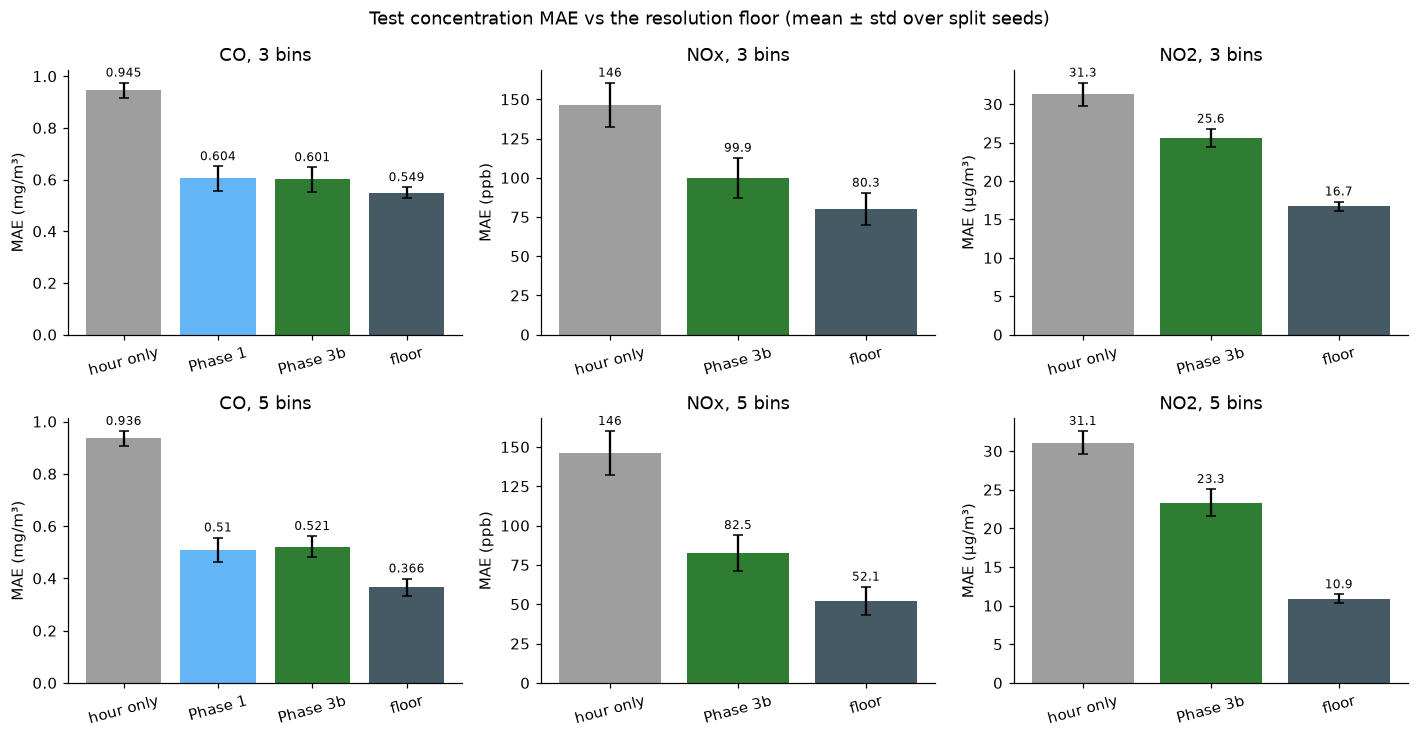

In [ ]:
order = [*MODELS, "resolution_floor"]
labels = {
    "HourOnlyBaseline": "hour only",
    "Phase1": "Phase 1",
    "Phase3b": "Phase 3b",
    "resolution_floor": "floor",
}

fig, axes = plt.subplots(
    len(BIN_COUNTS), len(GASES), figsize=(13, 3.4 * len(BIN_COUNTS))
)
for i, b in enumerate(BIN_COUNTS):
    for j, gas in enumerate(GASES):
        ax = axes[i, j]
        g = wide.xs((b, str(gas)), level=["bins", "gas"])
        names = [m for m in order if m in g and g[m].notna().any()]
        means, stds = g[names].mean(), g[names].std()
        bars = ax.bar(
            [labels[m] for m in names],
            means,
            yerr=stds,
            capsize=3,
            color=[COLORS[m] for m in names],
        )
        ax.bar_label(bars, fmt="%.3g", padding=2, fontsize=8)
        ax.set_title(f"{short(gas)}, {b} bins")
        ax.set_ylabel(f"MAE ({UNITS[short(gas)]})")
        ax.tick_params(axis="x", rotation=15)
fig.suptitle(
    "Test concentration MAE vs the resolution floor (mean ± std over split seeds)"
)
plt.tight_layout()
plt.savefig(config.paths.figure(PHASE, "test_mae_vs_floor.png"), bbox_inches="tight")
plt.show()

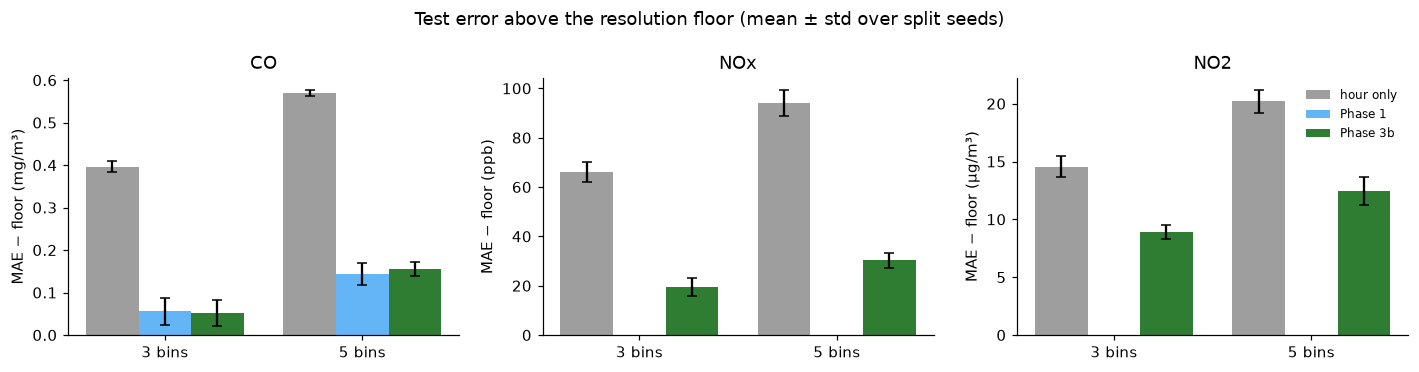

In [ ]:
# excess over the floor: how much of each model's error is the model, not the bins
excess = (
    wide[[m for m in MODELS]]
    .sub(wide["resolution_floor"], axis=0)
    .stack()
    .rename("excess")
    .reset_index()
)
excess["gas"] = excess["gas"].map(short)

fig, axes = plt.subplots(1, len(GASES), figsize=(13, 3.4))
for ax, gas in zip(axes, map(short, GASES), strict=True):
    e = excess[excess["gas"] == gas]
    width = 0.8 / len(MODELS)
    for k, name in enumerate(MODELS):
        stats = e[e["model"] == name].groupby("bins")["excess"].agg(["mean", "std"])
        if stats.empty:
            continue
        x = np.arange(len(BIN_COUNTS)) + (k - 1) * width
        ax.bar(
            x,
            stats["mean"],
            width,
            yerr=stats["std"],
            capsize=3,
            color=COLORS[name],
            label=labels[name],
        )
    ax.set_xticks(np.arange(len(BIN_COUNTS)), [f"{b} bins" for b in BIN_COUNTS])
    ax.set_title(gas)
    ax.set_ylabel(f"MAE − floor ({UNITS[gas]})")
axes[-1].legend(frameon=False, fontsize=8)
fig.suptitle("Test error above the resolution floor (mean ± std over split seeds)")
plt.tight_layout()
plt.savefig(
    config.paths.figure(PHASE, "test_excess_over_floor.png"), bbox_inches="tight"
)
plt.show()

## 8. Reading

Test, mean ± std over split seeds 0–2; models fit on train ∪ val.

- **Every model beats the hour of day on every gas, at both bin counts.** Phase 3b's skill (share of the hour baseline's MAE removed) is 0.365 ± 0.031 for CO, 0.319 ± 0.028 for NOx and 0.181 ± 0.006 for NO2 at 3 bins, and 0.443, 0.437 and 0.251 at 5 bins.
- **CO and NOx get close to the floor; NO2 does not.** At 3 bins Phase 3b closes 0.87 ± 0.07 of the gap between the hour baseline and the floor for CO and 0.71 ± 0.05 for NOx, but only 0.39 ± 0.01 for NO2, which stays 8.9 ± 0.6 µg/m³ above its floor. NO2's limit is the evidence (its sensors carry little NO2 information), not the bins.
- **3 vs 5 bins.** 5 bins lower the MAE for every gas (CO 0.601 → 0.521 mg/m³, NOx 99.9 → 82.5 ppb, NO2 25.6 → 23.3 µg/m³), but the floor drops faster (CO 0.549 → 0.366), so the error *above* the floor grows (CO 0.052 → 0.155) and the gap closed falls. Finer bins raise the ceiling, but each CPT row has fewer hours behind it. Log-likelihood is not comparable across bin counts.
- **Phase 3b vs Phase 1 on CO: the same point accuracy, a better posterior.** CO MAE is 0.601 vs 0.604 at 3 bins and 0.521 vs 0.510 at 5 bins; the paired skill of 3b over 1 is +0.006 ± 0.008 and −0.024 ± 0.018, within seed noise. Phase 3b puts more probability on the true CO bin (mean log-lik −0.569 vs −0.657 at 3 bins, −0.903 vs −1.012 at 5) and estimates NOx and NO2 as well.
- **Consistent with validation.** Phase 3b's 3-bin skill on validation was 0.37 (CO), 0.34 (NOx) and 0.16 (NO2); on test it is 0.37, 0.32 and 0.18. Raw MAEs are higher on test for CO (Phase 1: 0.604 vs 0.544 on val), but so is the floor (0.549 vs 0.461): the test weeks are harder to bin, not a worse fit, which is why skill and gap closed are the numbers to compare.
- **EM.** Every run is monotone and converged; Phase 3b converges in 9–14 iterations and Phase 1 in 3.